In [1]:
import jax_sn
import jax.numpy as jnp
import jax 
import numpy as onp
jax.config.update("jax_enable_x64", True)   

In [320]:
xs_data = jax_sn.domain.cross_sections.CrossSectionData(jnp.array([1.0]), jnp.ones((1,1,1)) * 0.9)

vertices, connectivity, layered_cross_section, source = jax_sn.domain.domain_generation.create_cartesian_setup(1, [[(1.0, 300)]], [xs_data], [1.0], 0)

quadrature_set = jax_sn.quadrature_set.create_tn_quadrature_set(2)

element = jax_sn.solution_domain.BasixLagrangianSimplex(0,1)

domain = jax_sn.domain.Domain.from_mesh_and_cross_sections((vertices, connectivity), element.face_template, layered_cross_section)

solution_domain = jax_sn.solution_domain.SolutionDomain.from_element_and_domain(element, domain)

toposort_angle = jax_sn.domain.TopologicalSortedAngle.from_domain_angle(domain, quadrature_set[0][0])

In [321]:
top = jax_sn.operators.transport_operator.TransportOperatorVmap(solution_domain.solution_domain_data, toposort_angle,0)
massoperator = jax_sn.operators.mass_operator.MassOperatorVmap.from_solution_domain_data(solution_domain.solution_domain_data)
rhs = massoperator.mv(jnp.ones_like(top.in_structure()))



In [322]:
mgop = jax_sn.operators.multi_group_operator.create_multi_group_operator(solution_domain, quadrature_set)

In [332]:
mgop.domain.cross_sections_indexed.cross_section_data

CrossSectionData(total=Array([[1.]], dtype=float64), scattering=Array([[[[0.9]]]], dtype=float64))

In [335]:
import equinox as eqx

class SGOP2(jax_sn.operators.base_linear_operator.AbstractLinearOperator_sn):
    
    mgop : jax_sn.operators.multi_group_operator.MultiGroupOperator
    
    @eqx.filter_jit
    def mv(self, x):
        mgop = self.mgop
        return mgop.moment_operator.mv(mgop.transport_operator.mv(mgop.discrete_operator.mv(x))) - mgop. mass_operator.mv( mgop.inscatter_operator.mv(x))

    def in_structure(self):
        return self.mgop.in_structure()

    def out_structure(self):
        return self.mgop.out_structure()

    def transpose(self):
        return None    
    
import lineax as lx

@lx.is_symmetric.register(SGOP2)
def _(operator : SGOP2):
    return False

sgop2 = SGOP2(mgop.to_single_group_operator(0))

In [336]:
import lineax as lx

bicgstab = lx.BiCGStab(1e-10,1e-10, max_steps=600)

gmres = lx.GMRES(1e-10,1e-10, max_steps=600, restart=30)



In [337]:
rhs_0 = jnp.ones_like(sgop2.in_structure())

rhs_precon = sgop2.mgop.moment_operator.mv(sgop2.mgop.transport_operator.inv(sgop2.mgop.mass_operator.mv(sgop2.mgop.discrete_operator.mv(rhs_0))))

In [338]:
solution = lx.linear_solve(sgop2, rhs_0, bicgstab)

In [339]:
solution_normal = lx.linear_solve(mgop.to_single_group_operator(0), rhs_precon, gmres)

In [340]:
solution.stats

{'max_steps': 600, 'num_steps': Array(163, dtype=int64)}

In [341]:
solution_normal.stats

{'max_steps': 600, 'num_steps': Array(3, dtype=int64)}

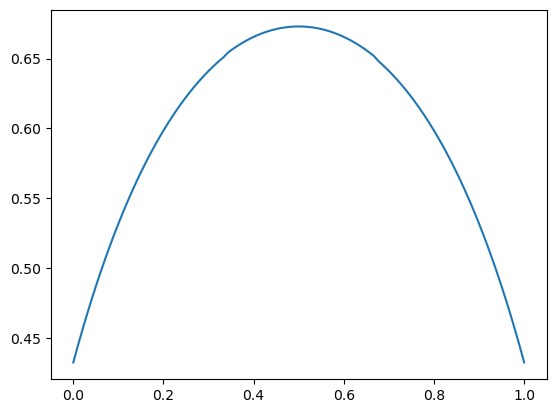

In [342]:
def plot_sol(solution):
    import matplotlib.pyplot as plt
    x = jnp.linspace(0,1,100)
    y = jnp.linspace(0.5,0.5, 100)

    xy = jnp.vstack([x]).T
    try: 
        sol = solution.value
    except:
        
        sol = solution
    sol_interp = solution_domain.interpolate(xy, sol[0, :,:])
    plt.plot(x, sol_interp)

plot_sol(rhs_precon)